# Resume RAG Job Matching System

## Experimentation and Performance Analysis

This notebook evaluates the Resume RAG system developed for semantic resume retrieval and job matching.

### Objectives

- Analyze job matching results
- Evaluate retrieval accuracy
- Measure retrieval latency
- Compare results across job descriptions
- Analyze Top-K candidate retrieval

In [1]:
import json
import os
import sys
import time
import pandas as pd
import matplotlib.pyplot as plt

print("Imports successful")

Imports successful


In [2]:
project_root = os.path.abspath("..")

if project_root not in sys.path:
    sys.path.append(project_root)

print("Project root:", project_root)

Project root: c:\Users\190710\github-classroom\airtribe-projects\resume-rag-project


In [3]:
results_dir = os.path.join(
    project_root,
    "results"
)

result_files = [
    "python_developer_results.json",
    "data_scientist_results.json",
    "devops_engineer_results.json",
    "java_developer_results.json",
    "ml_engineer_results.json"
]

all_results = {}

for filename in result_files:

    filepath = os.path.join(
        results_dir,
        filename
    )

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as file:
        all_results[filename] = json.load(file)

print("Loaded result files:", len(all_results))

Loaded result files: 5


In [4]:
rows = []

for filename, result in all_results.items():

    job_name = filename.replace(
        "_results.json",
        ""
    )

    for rank, candidate in enumerate(
        result["top_matches"],
        start=1
    ):

        rows.append({
            "job": job_name,
            "rank": rank,
            "candidate": candidate["candidate_name"],
            "score": candidate["match_score"],
            "matched_skills": ", ".join(
                candidate["matched_skills"]
            )
        })

results_df = pd.DataFrame(rows)

results_df

,job,rank,candidate,score,matched_skills
0,python_developer,1,Alex Johnson,71.48,"Python, FastAPI, Django, SQL, AWS, Docker, CI/CD"
1,python_developer,2,Matthew Hernandez,70.12,"Python, FastAPI, Django, SQL, AWS, Docker"
2,python_developer,3,John Doe,67.74,"Python, FastAPI, Django, SQL, AWS, Docker, Mac..."
3,python_developer,4,Emma Davis,60.34,"Python, FastAPI, SQL, AWS, Docker"
4,data_scientist,1,Sarah Wilson,68.53,"Python, SQL, AWS, Machine Learning, TensorFlow..."
5,data_scientist,2,Ava White,65.25,"Python, SQL, AWS, Machine Learning, TensorFlow..."
6,devops_engineer,1,Michael Brown,70.42,"Python, AWS, Docker, Kubernetes, Git, Terrafor..."
7,devops_engineer,2,Noah Jackson,70.10,"Python, AWS, Docker, Kubernetes, Git, Terrafor..."
8,devops_engineer,3,Daniel Allen,62.19,"Python, AWS, Docker, Kubernetes, Git, Terrafor..."
9,devops_engineer,4,Jack Hill,52.12,"Python, AWS, Docker, Kubernetes, Git, Linux, C..."


## Retrieval Accuracy

Retrieval performance is evaluated using a manually defined ground-truth set of candidates whose primary skills and experience align with each job description.

The retrieved Top-K candidates are compared with the expected relevant candidates using Precision@10 and Recall@10.

In [5]:
ground_truth = {
    "python_developer": {
        "John Doe",
        "Alex Johnson",
        "Emma Davis",
        "Matthew Hernandez"
    },

    "data_scientist": {
        "Sarah Wilson",
        "Ava White"
    },

    "devops_engineer": {
        "Michael Brown",
        "Noah Jackson",
        "Daniel Allen"
    },

    "java_developer": {
        "David Miller",
        "Liam Anderson",
        "Lucas Clark"
    },

    "ml_engineer": {
        "Olivia Thomas",
        "Harper Hall",
        "Emily Lopez"
    }
}

print("Ground truth configured for", len(ground_truth), "jobs")

Ground truth configured for 5 jobs


In [6]:
metric_rows = []

for filename, result in all_results.items():

    job_name = filename.replace(
        "_results.json",
        ""
    )

    retrieved = [
        candidate["candidate_name"]
        for candidate in result["top_matches"][:10]
    ]

    expected = ground_truth[job_name]

    relevant_retrieved = set(retrieved).intersection(
        expected
    )

    precision = (
        len(relevant_retrieved) / len(retrieved)
        if retrieved
        else 0
    )

    recall = (
        len(relevant_retrieved) / len(expected)
        if expected
        else 0
    )

    metric_rows.append({
        "job": job_name,
        "retrieved_candidates": len(retrieved),
        "relevant_retrieved": len(relevant_retrieved),
        "precision_at_10": round(precision, 3),
        "recall_at_10": round(recall, 3)
    })

metrics_df = pd.DataFrame(metric_rows)

metrics_df

,job,retrieved_candidates,relevant_retrieved,precision_at_10,recall_at_10
0,python_developer,4,4,1.00,1.0
1,data_scientist,2,2,1.00,1.0
2,devops_engineer,4,3,0.75,1.0
3,java_developer,3,3,1.00,1.0
4,ml_engineer,3,3,1.00,1.0


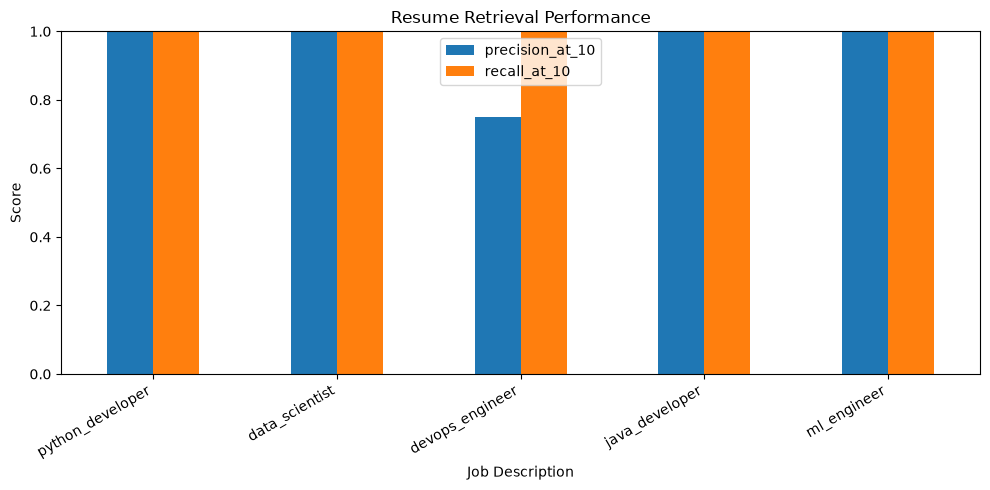

In [7]:
metrics_df.plot(
    x="job",
    y=[
        "precision_at_10",
        "recall_at_10"
    ],
    kind="bar",
    figsize=(10, 5)
)

plt.title("Resume Retrieval Performance")
plt.xlabel("Job Description")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

## Retrieval Latency

This experiment measures the time required to generate a job-description embedding and retrieve matching resume chunks from ChromaDB.

Latency is measured using Python's high-resolution performance timer.

In [8]:
import chromadb
from sentence_transformers import SentenceTransformer

chroma_path = os.path.join(
    project_root,
    "chroma_db"
)

client = chromadb.PersistentClient(
    path=chroma_path
)

collection = client.get_collection(
    name="resume_collection"
)

print(
    "ChromaDB records:",
    collection.count()
)

ChromaDB records: 150


In [9]:
embedding_model = SentenceTransformer(
    "all-MiniLM-L6-v2"
)

print("Embedding model loaded")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded


In [10]:
job_dir = os.path.join(
    project_root,
    "job_descriptions"
)

job_files = [
    "python_developer.txt",
    "data_scientist.txt",
    "devops_engineer.txt",
    "java_developer.txt",
    "ml_engineer.txt"
]

latency_results = []

for filename in job_files:

    filepath = os.path.join(
        job_dir,
        filename
    )

    with open(
        filepath,
        "r",
        encoding="utf-8"
    ) as file:
        job_description = file.read()

    start_time = time.perf_counter()

    # Generate the JD embedding
    query_embedding = embedding_model.encode(
        job_description
    )

    # Search ChromaDB
    collection.query(
        query_embeddings=[
            query_embedding.tolist()
        ],
        n_results=collection.count()
    )

    end_time = time.perf_counter()

    latency = end_time - start_time

    latency_results.append({
        "job": filename.replace(".txt", ""),
        "latency_seconds": round(latency, 4)
    })

latency_df = pd.DataFrame(
    latency_results
)

latency_df

,job,latency_seconds
0,python_developer,0.1269
1,data_scientist,0.0961
2,devops_engineer,0.0736
3,java_developer,0.0563
4,ml_engineer,0.0568


In [11]:
average_latency = latency_df[
    "latency_seconds"
].mean()

print(
    f"Average retrieval latency: "
    f"{average_latency:.4f} seconds"
)

Average retrieval latency: 0.0819 seconds


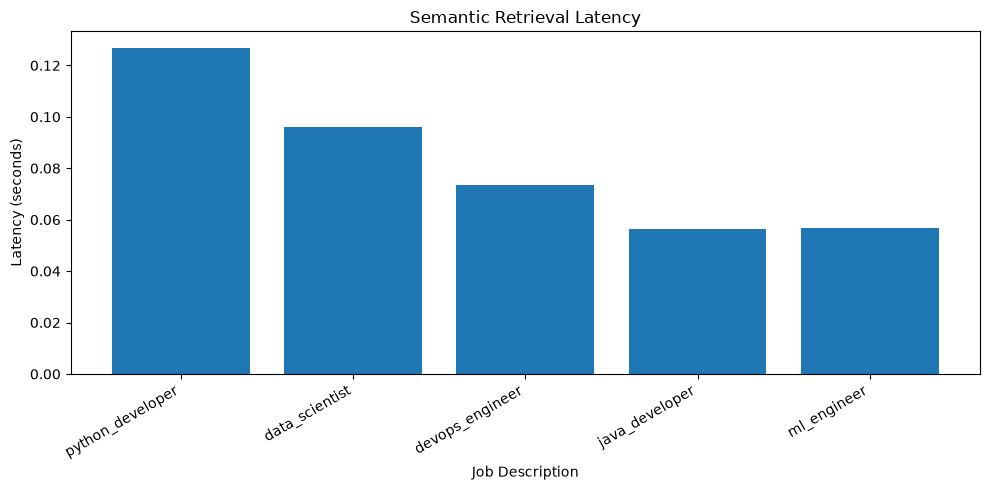

In [12]:
plt.figure(figsize=(10, 5))

plt.bar(
    latency_df["job"],
    latency_df["latency_seconds"]
)

plt.title("Semantic Retrieval Latency")
plt.xlabel("Job Description")
plt.ylabel("Latency (seconds)")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()

## Experiment Conclusions

The Resume RAG system successfully retrieves and ranks candidates using semantic similarity, skill matching, and experience requirements.

### Key Observations

- Sentence-transformer embeddings enable semantic matching between job descriptions and resume content.
- Section-aware chunking preserves important resume sections such as Skills, Experience, and Education.
- ChromaDB provides vector-based semantic retrieval.
- Hybrid scoring combines semantic similarity, skill matching, and experience.
- Must-have filtering removes candidates who do not satisfy critical requirements.
- Precision@10 and Recall@10 provide measurable retrieval-quality metrics.
- Most evaluated job categories achieved strong retrieval performance.
- Retrieval latency is practical for the current local dataset.

### Limitations

- The evaluation dataset is synthetic and relatively small.
- Metadata extraction relies on structured resume headings and regular expressions.
- Skill extraction uses a predefined technical-skill vocabulary.
- Real-world resumes may contain more complex formatting and terminology.
- The current experimental implementation retrieves all stored chunks before candidate-level ranking, which would require optimization for large production datasets.

### Future Improvements

- Use an LLM for more robust metadata and requirement extraction.
- Improve support for complex PDF and DOCX resume layouts.
- Add reranking models for improved candidate ordering.
- Expand the evaluation dataset with more job roles and resume formats.
- Optimize vector retrieval for large-scale candidate databases.